# CS920 · Lab 1 — Can we trust a good fit?

**Duration:** 50 minutes (including initial login/Jupyter setup).  
**Today's tools:** NumPy and Matplotlib; **no GPU needed**.

## 1. Start with an energy function

Let $x\in\mathbb R$ be an input and $y\in\mathbb R$ a candidate output. Choose a **feature map** $\phi:\mathbb R\to\mathbb R^d$ and a **weight vector** $v\in\mathbb R^d$. Define

$$
\boxed{E_{v,\phi}(x,y)=\bigl(\langle v,\phi(x)\rangle-y\bigr)^2.}
$$

**Why this energy?** It is nonnegative and is minimised (to zero) precisely when

$$
y=\langle v,\phi(x)\rangle.
$$

That is, $x$ and $y$ are **compatible** when the output agrees with a *linear combination of the features* of $x$. The predictor need not be linear in the original input $x$.

For a fixed input, our **inference rule** chooses the lowest-energy output:

$$
\widehat y_{v,\phi}(x)=\arg\min_{y\in\mathbb R}E_{v,\phi}(x,y)
=\langle v,\phi(x)\rangle.
$$

**How do we learn?** Energy and loss are different concepts, though they can coincide. **For this lab, we choose the per-example training loss to be the energy itself:**

$$
\ell_{v,\phi}(x,y)=E_{v,\phi}(x,y).
$$

Given training pairs $(x_1,y_1),\ldots,(x_n,y_n)$, the average training loss is

$$
\widehat L_{\mathrm{train}}(v;\phi)
=\frac1n\sum_{i=1}^n\bigl(\langle v,\phi(x_i)\rangle-y_i\bigr)^2.
$$

**Crucial distinction for Lab 1:** We **choose $\phi$ in advance and keep it fixed** while fitting the model. We **learn only $v$**:

$$
\widehat v_{\phi}=\arg\min_{v\in\mathbb R^d}\widehat L_{\mathrm{train}}(v;\phi).
$$

We will compare several *pre-chosen* feature maps and select among them using validation data; that is not the same as learning the features from training data. **In later labs, we will learn $\phi$ as well as $v$** (for example, using a neural network to learn the representation).

**Today's question:** If we minimise training energy, does the resulting model necessarily predict well on new examples? No probabilistic interpretation is needed to define the energy above.


# Lab 1：Energy-Based Model（基于能量的模型）

## 一、本节课的核心内容

本节主要介绍如何使用 **Energy Function（能量函数）** 建立模型，以及如何通过最小化损失来学习模型参数。

需要理解三个问题：

1. **模型如何定义？** 使用特征映射 $\phi$ 和权重向量 $v$ 构建能量函数。
2. **模型如何预测？** 找到使能量最小的候选输出 $y$。
3. **模型如何训练？** 利用训练数据寻找最优权重 $v$。

本节课的核心公式：

$$
\boxed{
E_{v,\phi}(x,y)
=
\left(\langle v,\phi(x)\rangle-y\right)^2
}
$$

---

## 二、Energy Function（能量函数）

### 2.1 能量函数的定义

课件定义：

$$
E_{v,\phi}(x,y)
=
\left(\langle v,\phi(x)\rangle-y\right)^2
$$

其中：

| 符号 | 英文名称 | 含义 |
|---|---|---|
| $x\in\mathbb R$ | Input | 输入数据 |
| $y\in\mathbb R$ | Candidate Output | 候选输出 |
| $\phi(x)$ | Feature Map | 将输入转换为特征向量 |
| $v$ | Weight Vector | 模型权重向量 |
| $d$ | Feature Dimension | 特征维度 |
| $\langle v,\phi(x)\rangle$ | Inner Product | 权重与特征的内积 |
| $E_{v,\phi}(x,y)$ | Energy Function | 衡量候选输出与模型预测之间的平方差 |

特别注意：

**能量函数中的 $y$ 是候选输出（Candidate Output），不一定是真实值。**

当能量函数被用于训练损失时，代入的 $y_i$ 才是训练数据中的真实值（Target / Label）。

### 2.2 为什么选择平方差作为能量？

能量函数可以写成：

$$
E(x,y)=(\hat y-y)^2
$$

其中：

$$
\hat y=\langle v,\phi(x)\rangle
$$

平方差具有两个重要性质。

**性质 1：非负性（Non-negativity）**

$$
E(x,y)\ge0
$$

因为任意实数的平方都不小于零。

**性质 2：当预测值与候选输出相等时，能量最小**

当：

$$
y=\langle v,\phi(x)\rangle
$$

有：

$$
E(x,y)=0
$$

因此：

$$
\boxed{
E(x,y)=0
\iff
y=\langle v,\phi(x)\rangle
}
$$

课件将这种情况称为：

**Compatibility（相容性）**：当输出 $y$ 与输入 $x$ 的特征线性组合一致时，两者是相容的。

---

## 三、Feature Map（特征映射）

### 3.1 特征映射是什么？

课件定义：

$$
\phi:\mathbb R\to\mathbb R^d
$$

表示将一个实数输入转换为一个 $d$ 维特征向量。

例如，定义：

$$
\phi(x)=(1,x,x^2)
$$

当：

$$
x=2
$$

得到：

$$
\phi(2)=(1,2,4)
$$

原本的输入只有一个数字，现在被转换为包含三个元素的向量。

因此：

$$
d=3
$$

### 3.2 为什么要使用特征映射？

假设模型直接使用原始输入：

$$
\hat y=v_0+v_1x
$$

那么只能表示一次多项式。

如果使用：

$$
\phi(x)=(1,x,x^2)
$$

则可以建立二次多项式模型：

$$
\hat y=v_0+v_1x+v_2x^2
$$

如果使用：

$$
\phi(x)=(1,x,x^2,x^3)
$$

则可以建立三次多项式模型：

$$
\hat y=v_0+v_1x+v_2x^2+v_3x^3
$$

这说明：

**通过改变特征映射，即使模型只是特征的线性组合，也可以表示原始输入 $x$ 的非线性关系。**

### 3.3 什么是线性组合？

假设：

$$
\phi(x)=(1,x,x^2)
$$

权重为：

$$
v=(v_0,v_1,v_2)
$$

那么两个向量的内积为：

$$
\begin{aligned}
\langle v,\phi(x)\rangle
&=(v_0,v_1,v_2)\cdot(1,x,x^2)\\
&=v_0+v_1x+v_2x^2
\end{aligned}
$$

例如：

$$
v=(1,2,3)
$$

则：

$$
\boxed{
\hat y=1+2x+3x^2
}
$$

虽然这个函数关于 $x$ 是非线性的，但是它关于特征向量 $\phi(x)$ 和权重 $v$ 是线性的。

---

## 四、Inference Rule（推断规则）

### 4.1 什么是 Inference？

Inference 表示：

**在模型参数已经确定的情况下，根据输入 $x$ 计算最合适的输出。**

课件给出：

$$
\boxed{
\hat y_{v,\phi}(x)
=
\arg\min_{y\in\mathbb R}E_{v,\phi}(x,y)
}
$$

意思是：

在所有可能的候选输出 $y$ 中，找到能够使能量最小的那个值。

### 4.2 argmin 是什么意思？

数学表达式：

$$
\arg\min_y f(y)
$$

表示：

**寻找使函数 $f(y)$ 取得最小值的自变量 $y$。**

例如：

$$
f(y)=(y-5)^2
$$

显然：

$$
f(5)=0
$$

因此：

$$
\arg\min_y (y-5)^2=5
$$

需要区分：

| 数学表达式 | 含义 | 结果 |
|---|---|---|
| $\min_y f(y)$ | 最小函数值 | 0 |
| $\arg\min_y f(y)$ | 使函数最小的自变量 | 5 |

注意：

**min 返回最小值，argmin 返回使函数达到最小值的位置或参数。**

### 4.3 将 argmin 应用到能量函数

能量函数：

$$
E_{v,\phi}(x,y)
=
\left(\langle v,\phi(x)\rangle-y\right)^2
$$

因为平方差在：

$$
y=\langle v,\phi(x)\rangle
$$

时取得最小值零，所以：

$$
\boxed{
\hat y_{v,\phi}(x)
=
\arg\min_{y\in\mathbb R}
E_{v,\phi}(x,y)
=
\langle v,\phi(x)\rangle
}
$$

这就是模型的预测公式。

### 4.4 具体案例

假设：

$$
\phi(x)=(1,x,x^2)
$$

$$
v=(1,2,3)
$$

那么：

$$
\hat y=1+2x+3x^2
$$

当：

$$
x=2
$$

模型预测：

$$
\hat y=1+2(2)+3(2^2)=17
$$

此时能量函数为：

$$
E(2,y)=(17-y)^2
$$

不同候选输出对应的能量为：

| 候选输出 $y$ | 能量 $E(2,y)$ |
|---|---|
| 10 | 49 |
| 15 | 4 |
| 16 | 1 |
| 17 | 0 |
| 18 | 1 |
| 20 | 9 |

因此：

$$
\boxed{
\arg\min_y E(2,y)=17
}
$$

模型最终选择：

$$
\boxed{\hat y=17}
$$

**总结：Inference 就是寻找能量最低的输出。**

---

## 五、Learning（模型训练）

### 5.1 为什么需要训练？

前面的推断过程假设权重 $v$ 已经确定。

但实际机器学习中，权重通常是未知的，需要利用训练数据学习。

假设使用二次多项式：

$$
\hat y=v_0+v_1x+v_2x^2
$$

需要通过训练数据确定：

$$
v_0,\quad v_1,\quad v_2
$$

### 5.2 训练数据

假设有以下数据：

| 样本编号 $i$ | 输入 $x_i$ | 真实值 $y_i$ |
|---|---|---|
| 1 | 1 | 2 |
| 2 | 2 | 5 |
| 3 | 3 | 10 |

对应训练样本：

$$
(x_1,y_1)=(1,2)
$$

$$
(x_2,y_2)=(2,5)
$$

$$
(x_3,y_3)=(3,10)
$$

训练时，$y_i$ 是已知的真实值。

模型需要寻找权重 $v$，使预测值：

$$
\hat y_i=\langle v,\phi(x_i)\rangle
$$

尽可能接近：

$$
y_i
$$

---

## 六、Loss Function（损失函数）

### 6.1 Energy 和 Loss 有什么区别？

Energy Function 和 Loss Function 是不同的概念。

- **Energy**：衡量输入与某个候选输出的相容程度，能量越低越相容。
- **Loss**：衡量模型在训练样本上的预测表现，用于优化模型参数。

在本次实验中，课件明确规定：

$$
\boxed{
\ell_{v,\phi}(x,y)=E_{v,\phi}(x,y)
}
$$

即：

**本次实验直接将能量函数作为每个训练样本的损失函数。**

因此：

$$
\ell_{v,\phi}(x,y)
=
\left(\langle v,\phi(x)\rangle-y\right)^2
$$

这是平方误差损失（Squared Error Loss）。

### 6.2 平均训练损失

给定：

$$
(x_1,y_1),\ldots,(x_n,y_n)
$$

平均训练损失定义为：

$$
\boxed{
\widehat L_{\mathrm{train}}(v;\phi)
=
\frac1n
\sum_{i=1}^{n}
\left(
\langle v,\phi(x_i)\rangle-y_i
\right)^2
}
$$

这个公式可以理解为：

$$
\text{Average Training Loss}
=
\frac{\text{所有训练样本平方误差之和}}{\text{训练样本数量}}
$$

它就是均方误差（Mean Squared Error，MSE）。

### 6.3 具体案例

仍然使用：

$$
\phi(x)=(1,x,x^2)
$$

模型：

$$
\hat y=v_0+v_1x+v_2x^2
$$

训练数据：

$$
(1,2),\quad(2,5),\quad(3,10)
$$

平均损失为：

$$
\begin{aligned}
\widehat L_{\mathrm{train}}
=\frac13\big[
&(v_0+v_1+v_2-2)^2\\
+&(v_0+2v_1+4v_2-5)^2\\
+&(v_0+3v_1+9v_2-10)^2
\big]
\end{aligned}
$$

如果选择：

$$
v=(1,0,1)
$$

则模型为：

$$
\hat y=1+x^2
$$

预测结果：

| 输入 $x$ | 真实值 $y$ | 预测值 $\hat y$ | 平方误差 |
|---|---|---|---|
| 1 | 2 | 2 | 0 |
| 2 | 5 | 5 | 0 |
| 3 | 10 | 10 | 0 |

所以：

$$
\widehat L_{\mathrm{train}}
=
\frac{0+0+0}{3}
=
0
$$

这组权重能够完美拟合当前训练样本。

---

## 七、训练过程中的 argmin

课件定义：

$$
\boxed{
\hat v_\phi
=
\arg\min_{v\in\mathbb R^d}
\widehat L_{\mathrm{train}}(v;\phi)
}
$$

意思是：

**在所有可能的权重向量中，找到使平均训练损失最小的那个权重向量。**

这里需要特别注意：

### 7.1 Inference 和 Learning 的区别

**Inference（预测）**

$$
\hat y_{v,\phi}(x)
=
\arg\min_y E_{v,\phi}(x,y)
$$

在模型权重固定时，寻找最优输出 $y$。

**Learning（训练）**

$$
\hat v_\phi
=
\arg\min_v \widehat L_{\mathrm{train}}(v;\phi)
$$

在训练数据与特征映射固定时，寻找最优权重 $v$。

| 比较 | Inference | Learning |
|---|---|---|
| 中文 | 推断、预测 | 学习、训练 |
| 优化变量 | $y$ | $v$ |
| 固定内容 | 输入 $x$、特征映射 $\phi$、权重 $v$ | 训练数据、特征映射 $\phi$ |
| 优化目标 | 最小化单个输入的能量 | 最小化平均训练损失 |
| 得到结果 | 预测值 $\hat y$ | 最优权重 $\hat v$ |

**这是本节课最重要的两个 argmin。**

---

## 八、为什么本次实验固定特征映射 $\phi$？

课件强调：

> We choose $\phi$ in advance and keep it fixed while fitting the model. We learn only $v$.

中文：

**在训练模型前预先选择特征映射 $\phi$，训练过程中保持不变，只学习权重向量 $v$。**

### 8.1 举例：选择不同的多项式特征

可以预先定义：

**一次多项式：**

$$
\phi_1(x)=(1,x)
$$

对应：

$$
\hat y=v_0+v_1x
$$

**二次多项式：**

$$
\phi_2(x)=(1,x,x^2)
$$

对应：

$$
\hat y=v_0+v_1x+v_2x^2
$$

**三次多项式：**

$$
\phi_3(x)=(1,x,x^2,x^3)
$$

对应：

$$
\hat y=v_0+v_1x+v_2x^2+v_3x^3
$$

比较：

| 特征映射 | 模型 | 特征维度 |
|---|---|---|
| $\phi_1(x)$ | 一次多项式 | $d=2$ |
| $\phi_2(x)$ | 二次多项式 | $d=3$ |
| $\phi_3(x)$ | 三次多项式 | $d=4$ |

在每次训练中：

1. 先选择一个特征映射。
2. 固定该特征映射。
3. 利用训练数据学习权重 $v$。
4. 使用验证集评价训练好的模型。
5. 比较不同预设特征映射的表现。

这里需要区分：

**选择不同的预设特征映射，不等于在训练过程中学习特征映射。**

### 8.2 后续实验会有什么不同？

在后续神经网络实验中，不仅可以学习权重，还可以学习特征表示。

例如：

$$
\phi_\theta(x)
$$

其中 $\theta$ 是特征提取部分的可训练参数。

模型可以写成：

$$
\hat y=\langle v,\phi_\theta(x)\rangle
$$

此时模型需要同时学习：

$$
v,\quad\theta
$$

因此，神经网络可以自动学习适合当前任务的特征表示，而不完全依赖人工预先定义特征。

---

## 九、训练误差最小，是否意味着预测效果最好？

课件提出：

> If we minimise training energy, does the resulting model necessarily predict well on new examples?

即：

**如果最小化训练能量，模型一定能够很好地预测新样本吗？**

答案是：

$$
\boxed{\text{不一定}}
$$

原因在于：

训练损失衡量模型对已有训练数据的拟合能力，而机器学习更重要的目标是对新数据的预测能力。

### 9.1 Underfitting（欠拟合）

当模型过于简单时，可能无法捕捉数据的真实规律。

例如，实际关系是二次函数，但使用一次多项式拟合：

$$
\hat y=v_0+v_1x
$$

模型可能无法充分拟合训练数据，也无法很好地预测新数据。

这叫作欠拟合。

### 9.2 Overfitting（过拟合）

当模型过于复杂时，可能把训练数据中的随机噪声也拟合进去。

例如，只有少量训练样本，却使用十次多项式：

$$
\hat y=v_0+v_1x+\cdots+v_{10}x^{10}
$$

它可能取得非常低的训练损失，但在新的数据上表现较差。

这叫作过拟合。

### 9.3 Validation Data（验证集）

为了选择更合适的模型，可以将数据分为：

- **Training Set（训练集）**：用于学习模型参数。
- **Validation Set（验证集）**：用于比较不同模型与超参数，例如多项式次数。
- **Test Set（测试集）**：用于在模型选择完成后评估最终泛化表现。

例如：

| 多项式次数 | 训练误差 | 验证误差 | 可能情况 |
|---|---|---|---|
| $k=1$ | 较高 | 较高 | 可能欠拟合 |
| $k=2$ | 较低 | 较低 | 可能更合适 |
| $k=10$ | 很低 | 较高 | 可能过拟合 |

以上只是示意情况，实际结果取决于具体数据。

**最终目标不是仅仅让训练误差最小，而是希望模型具有良好的泛化能力（Generalisation）。**

---

## 十、使用 NumPy 实现上述模型

本次实验使用 NumPy，可以通过最小二乘法（Least Squares）计算最优权重。

假设：

$$
\phi(x)=(1,x,x^2)
$$

训练数据：

$$
x=[1,2,3]
$$

$$
y=[2,5,10]
$$

对应代码：

```python
import numpy as np

# Training data
x = np.array([1, 2, 3])
y = np.array([2, 5, 10])

# Polynomial degree
degree = 2

# Feature matrix: [1, x, x^2]
Phi = np.vander(
    x,
    N=degree + 1,
    increasing=True
)

print("Feature matrix:")
print(Phi)

# Learn model weights using least squares
v = np.linalg.lstsq(Phi, y, rcond=None)[0]

print("Weights:")
print(v)

# Prediction
y_pred = Phi @ v

# Average training loss (MSE)
loss = np.mean((y_pred - y) ** 2)

print("Predictions:")
print(y_pred)

print("Training loss:")
print(loss)
```

### 10.1 特征矩阵是什么？

上述代码中：

```python
Phi = np.vander(x, N=degree + 1, increasing=True)
```

生成：

$$
\Phi=
\begin{bmatrix}
1&1&1\\
1&2&4\\
1&3&9
\end{bmatrix}
$$

矩阵的每一行代表一个输入对应的特征向量。

例如：

$$
\phi(2)=(1,2,4)
$$

就是矩阵第二行。

对于 $n$ 个样本和 $d$ 个特征：

$$
\Phi\in\mathbb R^{n\times d}
$$

### 10.2 np.linalg.lstsq 的作用

代码：

```python
v = np.linalg.lstsq(Phi, y, rcond=None)[0]
```

表示求解最小二乘问题：

$$
\boxed{
\hat v
=
\arg\min_v\|\Phi v-y\|_2^2
}
$$

其优化目标与最小化平均训练损失相同，因为乘以常数 $1/n$ 不会改变最优权重。

在这个例子中，得到：

$$
\hat v\approx(1,0,1)
$$

因此训练后的预测函数为：

$$
\boxed{\hat y=1+x^2}
$$

### 10.3 预测值如何计算？

代码：

```python
y_pred = Phi @ v
```

表示矩阵乘法：

$$
\hat{\mathbf y}=\Phi v
$$

其中：

$$
\Phi\in\mathbb R^{3\times3}
$$

$$
v\in\mathbb R^3
$$

所以：

$$
\hat{\mathbf y}\in\mathbb R^3
$$

预测结果约为：

$$
\hat{\mathbf y}=
\begin{bmatrix}
2\\
5\\
10
\end{bmatrix}
$$

### 10.4 为什么使用 mean？

代码：

```python
loss = np.mean((y_pred - y) ** 2)
```

对应数学公式：

$$
\widehat L_{\mathrm{train}}
=
\frac1n\sum_{i=1}^n(\hat y_i-y_i)^2
$$

这里：

- `y_pred - y`：计算每个样本的预测误差。
- `** 2`：对每个误差求平方。
- `np.mean()`：计算所有平方误差的平均值。

这就是均方误差（MSE）。

---

## 十一、完整知识框架

整个训练与预测流程可以概括为：

### 训练阶段（Training）

**Step 1：选择特征映射**

$$
\phi:\mathbb R\to\mathbb R^d
$$

**Step 2：将训练输入转换成特征矩阵**

$$
\Phi=
\begin{bmatrix}
\phi(x_1)^T\\
\phi(x_2)^T\\
\vdots\\
\phi(x_n)^T
\end{bmatrix}
$$

**Step 3：建立预测模型**

$$
\hat{\mathbf y}=\Phi v
$$

**Step 4：计算平均训练损失**

$$
\widehat L_{\mathrm{train}}
=
\frac1n\|\Phi v-\mathbf y\|_2^2
$$

**Step 5：学习最优权重**

$$
\boxed{
\hat v=\arg\min_v\widehat L_{\mathrm{train}}(v;\phi)
}
$$

### 预测阶段（Inference）

当输入一个新的数据点 $x_{\mathrm{new}}$：

首先计算特征：

$$
\phi(x_{\mathrm{new}})
$$

然后利用已经学习好的权重：

$$
\boxed{
\hat y_{\mathrm{new}}
=
\langle\hat v,\phi(x_{\mathrm{new}})\rangle
}
$$

预测时不需要预先知道真实输出。

---

## 十二、重点总结

| 知识点 | 核心公式或解释 |
|---|---|
| Feature Map | $\phi:\mathbb R\to\mathbb R^d$ |
| Weight Vector | $v\in\mathbb R^d$ |
| Prediction | $\hat y=\langle v,\phi(x)\rangle$ |
| Energy Function | $E(x,y)=(\hat y-y)^2$ |
| Inference | $\hat y=\arg\min_yE(x,y)$ |
| Per-example Loss | $\ell(x,y)=E(x,y)$（本次实验） |
| Average Training Loss | $\widehat L=\frac1n\sum_i(\hat y_i-y_i)^2$ |
| Learning | $\hat v=\arg\min_v\widehat L(v;\phi)$ |
| Feature Matrix | $\Phi\in\mathbb R^{n\times d}$ |
| Least Squares | $\hat v=\arg\min_v\|\Phi v-\mathbf y\|_2^2$ |
| Validation | 比较不同预设模型在验证数据上的表现 |
| Generalisation | 模型对未见过的新数据的预测能力 |

**本节最核心的思想：**

$$
\boxed{
\text{固定特征映射 }\phi
\;\longrightarrow\;
\text{学习权重 }v
\;\longrightarrow\;
\text{得到预测 }\hat y
}
$$

同时记住两个不同的优化问题：

$$
\boxed{
\text{Inference：}\quad
\hat y=\arg\min_y E(x,y)
}
$$

$$
\boxed{
\text{Learning：}\quad
\hat v=\arg\min_v\widehat L_{\mathrm{train}}(v;\phi)
}
$$

前者优化输出，后者优化参数。

---

## 十三、课后练习

假设：

$$
\phi(x)=(1,x,x^2)
$$

$$
v=(2,1,3)
$$

当输入：

$$
x=2
$$

请完成以下问题：

1. 计算特征向量 $\phi(2)$。
2. 计算模型预测值 $\hat y$。
3. 如果真实值为 $y=15$，计算能量 $E_{v,\phi}(2,15)$。
4. 在这个例子中，$\phi$ 和 $v$ 哪一个是本次实验需要通过训练数据学习的？

这四道题分别对应 Feature Map、Inference、Energy 和 Learning。


### Getting started (first practical only)

In a terminal on a DCS lab desktop:

```bash
module load cs920-python
mkdir -p ~/cs920/lab1
cd ~/cs920
cp -r /modules/cs920/labs/lab1 .
python -m venv venv          # once only; skip if ~/cs920/venv already exists
source venv/bin/activate
jupyter lab
```

Open `lab1/lab1.ipynb` in JupyterLab. Press **Shift+Enter** to run a code cell. If Firefox does not open automatically, copy the `http://localhost:...` URL from the terminal into Firefox.

**Time budget:** setup (10–15 min) → energy + data (6 min) → fitting (10 min) → losses (9 min) → unseen-data reveal + discussion (10 min). The optional extension can be done after class.

If setup is taking too long, ask your TA. The main goal today is to understand the experiment, not memorise Jupyter commands.


## 2. Observe the training data

We have noisy measurements of an unknown relationship between a **scalar input** $x$ and an output $y$. We also have a separate **validation set**, which we will not plot yet.

Run the next cell. There is no coding required.

Training examples: 18
Validation examples: 70


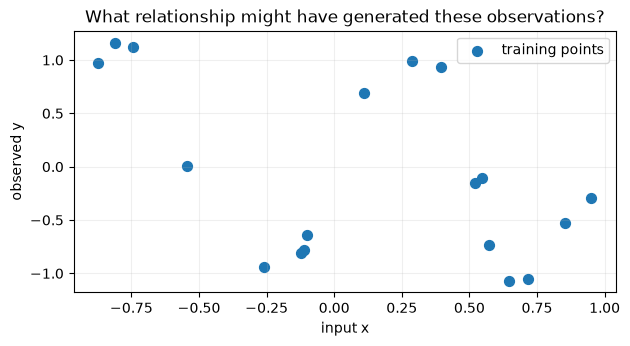

In [2]:
import numpy as np
import matplotlib.pyplot as plt

with np.load("lab1_data.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_val, y_val = data["x_val"], data["y_val"]

print(f"Training examples: {len(x_train)}")
print(f"Validation examples: {len(x_val)}")

# 创建画布 和 画布区域
fig, ax = plt.subplots(figsize=(7, 3.4))
# scatter() 是 Matplotlib 的散点图函数。它会将输入数组中的数据两两配对，然后将每一对数据绘制为一个点。
ax.scatter(x_train, y_train, s=50, label="training points")
# 设置x轴，y轴，标题信息
ax.set(xlabel="input x", ylabel="observed y", title="What relationship might have generated these observations?")
# 添加网格线
ax.grid(alpha=0.2)
# 显示图例
ax.legend()
plt.show()

**Stop and predict (1 minute).** Could a straight line describe these points well? Could a very flexible curve do *too* well? Discuss with the person next to you before continuing.

## 3. Choose polynomial features; learn only $v$ — coding task A

For each polynomial **degree $k$**, we *specify* the feature map

$$
\phi_k(x)=(1,x,x^2,\ldots,x^k)\in\mathbb R^{k+1}.
$$

This is the general setup from Section 1 with **feature dimension $d=k+1$** and weight vector $v=(v_0,\ldots,v_k)\in\mathbb R^{k+1}$. The energy and prediction become

$$
E_{v,\phi_k}(x,y)=\bigl(\langle v,\phi_k(x)\rangle-y\bigr)^2,
\qquad
\widehat y_{v,\phi_k}(x)=v_0+v_1x+\cdots+v_kx^k.
$$

A polynomial is therefore **linear in its features**, though generally nonlinear in $x$.

**What is fixed, and what is learnt?** When fitting degree $k$, $\phi_k$ is **fixed**. Only the coefficients $v_0,\ldots,v_k$ are estimated. Later we will compare a few *different pre-chosen* degrees using validation data.

Let $\Phi$ be the **feature matrix**, whose $i$th row is $\phi_k(x_i)$. We find $v$ by least squares, minimising the average training energy. In NumPy, `np.vander(x, N=degree + 1, increasing=True)` constructs $\Phi$.

**Fill in the two `TODO` lines** using `np.vander` and `np.linalg.lstsq`. The prediction function is provided.


# Polynomial Regression（多项式回归）：原文翻译与讲解

## 1. 定义特征映射（Feature Map）

### 原文

> For each polynomial **degree $k$**, we *specify* the feature map
>
> $$
> \phi_k(x)=(1,x,x^2,\ldots,x^k)\in\mathbb R^{k+1}.
> $$

### 中文翻译

对于每一个多项式次数（Polynomial Degree）$k$，我们预先指定对应的特征映射（Feature Map）：

$$
\phi_k(x)=(1,x,x^2,\ldots,x^k)\in\mathbb R^{k+1}
$$

### 公式讲解

特征映射 $\phi_k$ 的作用，是把一个输入数字 $x$ 转换成由它的不同次幂组成的向量。

其中：

- $x$：输入数据。
- $k$：预先选定的多项式次数。
- $\phi_k(x)$：输入 $x$ 对应的特征向量。
- $\mathbb R^{k+1}$：包含 $k+1$ 个实数的向量空间。

**为什么维度是 $k+1$？**

因为特征从 $x^0$ 开始，到 $x^k$ 结束：

$$
x^0,x^1,x^2,\ldots,x^k
$$

一共有 $k+1$ 项。

例如，当 $k=2$：

$$
\phi_2(x)=(1,x,x^2)
$$

输入 $x=3$：

$$
\phi_2(3)=(1,3,9)
$$

当 $k=3$：

$$
\phi_3(x)=(1,x,x^2,x^3)
$$

输入 $x=2$：

$$
\phi_3(2)=(1,2,4,8)
$$

**注意：** 特征映射的第一个元素是 1，对应多项式中的常数项（Intercept / Bias）。

---

## 2. 特征维度和权重向量（Feature Dimension & Weight Vector）

### 原文

> This is the general setup from Section 1 with **feature dimension $d=k+1$** and weight vector $v=(v_0,\ldots,v_k)\in\mathbb R^{k+1}$.

### 中文翻译

这与第一节介绍的一般模型框架相同，其中**特征维度为 $d=k+1$**，权重向量定义为：

$$
v=(v_0,\ldots,v_k)\in\mathbb R^{k+1}
$$

### 公式讲解

**特征维度（Feature Dimension）**

$$
\boxed{d=k+1}
$$

它表示模型使用多少个特征。

例如：

| 多项式次数 $k$ | 特征向量 | 特征维度 $d$ |
|---|---|---|
| 1 | $(1,x)$ | 2 |
| 2 | $(1,x,x^2)$ | 3 |
| 3 | $(1,x,x^2,x^3)$ | 4 |

**权重向量（Weight Vector）**

$$
v=(v_0,v_1,\ldots,v_k)
$$

向量中的每一个参数对应一个特征：

| 特征 | 对应权重 |
|---|---|
| $1$ | $v_0$ |
| $x$ | $v_1$ |
| $x^2$ | $v_2$ |
| $\vdots$ | $\vdots$ |
| $x^k$ | $v_k$ |

例如：

$$
\phi_2(x)=(1,x,x^2)
$$

$$
v=(2,1,3)
$$

那么模型的预测就是将每个特征乘以对应权重后相加：

$$
\hat y=2\times1+1\times x+3\times x^2
$$

即：

$$
\boxed{\hat y=2+x+3x^2}
$$

---

## 3. 能量函数与预测函数（Energy & Prediction）

### 原文

> The energy and prediction become
>
> $$
> E_{v,\phi_k}(x,y)=\bigl(\langle v,\phi_k(x)\rangle-y\bigr)^2,
> \qquad
> \widehat y_{v,\phi_k}(x)=v_0+v_1x+\cdots+v_kx^k.
> $$

### 中文翻译

在使用多项式特征映射之后，能量函数和预测函数分别变为：

$$
E_{v,\phi_k}(x,y)
=
\left(\langle v,\phi_k(x)\rangle-y\right)^2
$$

$$
\widehat y_{v,\phi_k}(x)
=
v_0+v_1x+\cdots+v_kx^k
$$

### 公式讲解

**预测函数（Prediction Function）**

先计算权重与特征的内积：

$$
\begin{aligned}
\langle v,\phi_k(x)\rangle
&=(v_0,\ldots,v_k)\cdot(1,x,\ldots,x^k)\\
&=v_0+v_1x+\cdots+v_kx^k
\end{aligned}
$$

因此：

$$
\boxed{
\hat y=\langle v,\phi_k(x)\rangle
}
$$

**能量函数（Energy Function）**

将预测值代入能量公式：

$$
\boxed{
E_{v,\phi_k}(x,y)=(\hat y-y)^2
}
$$

这里：

- $\hat y$：模型预测值。
- $y$：候选输出；在训练时取训练样本的真实值。
- $E$：预测值与所给输出之间的平方差。

**计算案例**

假设：

$$
k=2,\quad v=(2,1,3),\quad x=2
$$

首先计算特征：

$$
\phi_2(2)=(1,2,4)
$$

预测值为：

$$
\begin{aligned}
\hat y
&=\langle(2,1,3),(1,2,4)\rangle\\
&=2+2+12\\
&=16
\end{aligned}
$$

如果训练样本的真实值为：

$$
y=15
$$

那么：

$$
E_{v,\phi_2}(2,15)=(16-15)^2=1
$$

所以：

$$
\boxed{\hat y=16,\qquad E=1}
$$

---

## 4. 为什么多项式在特征上是线性的？

### 原文

> A polynomial is therefore **linear in its features**, though generally nonlinear in $x$.

### 中文翻译

因此，多项式模型**对于特征是线性的（Linear in its Features）**，但对于原始输入 $x$，通常是非线性的。

### 讲解

这是本段内容中比较容易混淆的知识点。

假设：

$$
\phi_2(x)=(1,x,x^2)
$$

$$
v=(v_0,v_1,v_2)
$$

预测模型为：

$$
\hat y=v_0+v_1x+v_2x^2
$$

**从原始输入 x 的角度看：**

由于存在 $x^2$，所以它一般不是关于 $x$ 的一次函数。

例如：

$$
\hat y=2+x+3x^2
$$

这是一个二次多项式。

**从特征的角度看：**

假设将特征表示为：

$$
z_0=1,\quad z_1=x,\quad z_2=x^2
$$

那么预测变为：

$$
\hat y=v_0z_0+v_1z_1+v_2z_2
$$

它是特征向量的线性组合。

因此：

$$
\boxed{
\text{对特征 }\phi_k(x)\text{ 线性}
\ne
\text{对原始输入 }x\text{ 线性}
}
$$

补充一个术语细节：因为特征向量中包含常数项 1，所以模型对原始输入常被称为仿射或多项式函数；这里的“线性”主要指它对特征向量和权重系数采用线性组合的形式。

这也是多项式回归仍然能够使用线性最小二乘法求解的原因。

---

## 5. 哪些内容固定，哪些内容需要学习？

### 原文

> **What is fixed, and what is learnt?** When fitting degree $k$, $\phi_k$ is **fixed**. Only the coefficients $v_0,\ldots,v_k$ are estimated. Later we will compare a few *different pre-chosen* degrees using validation data.

### 中文翻译

**哪些部分是固定的？哪些部分需要学习？**

当我们拟合一个指定次数 $k$ 的多项式时，特征映射 $\phi_k$ 是**固定的**。

训练过程中只需要估计多项式系数：

$$
v_0,v_1,\ldots,v_k
$$

之后，我们会使用验证数据（Validation Data），比较几个**事先选定的不同多项式次数**。

### 讲解

例如，假设我们选择：

$$
k=2
$$

那么特征映射已经确定：

$$
\phi_2(x)=(1,x,x^2)
$$

训练过程中不会把它变成：

$$
(1,x,x^2,x^3)
$$

因为那相当于更换了特征映射和模型次数。

但权重：

$$
v=(v_0,v_1,v_2)
$$

可以通过训练不断调整。

例如，某一组参数：

$$
v=(1,2,3)
$$

对应：

$$
\hat y=1+2x+3x^2
$$

学习之后可能得到：

$$
\hat v=(2,0.5,1.2)
$$

对应新的预测函数：

$$
\hat y=2+0.5x+1.2x^2
$$

这只是说明权重如何改变的假设性例子，不是课件中某组训练数据的实际结果。

整个过程中，多项式次数仍然是 2。

**这里需要区分两件事：**

- **Parameter Learning（参数学习）**：在固定 $k$ 时，训练权重 $v$。
- **Model Selection（模型选择）**：使用验证集比较预先选择的不同次数 $k$。

---

## 6. Feature Matrix（特征矩阵）

### 原文

> Let $\Phi$ be the **feature matrix**, whose $i$th row is $\phi_k(x_i)$. We find $v$ by least squares, minimising the average training energy.

### 中文翻译

设 $\Phi$ 为**特征矩阵（Feature Matrix）**，它的第 $i$ 行就是训练输入 $x_i$ 对应的特征向量 $\phi_k(x_i)$。

我们通过**最小二乘法（Least Squares）**寻找权重 $v$，使平均训练能量最小。

### 公式讲解

假设有 $n$ 个训练样本：

$$
x_1,x_2,\ldots,x_n
$$

每个输入经过特征映射后得到：

$$
\phi_k(x_i)=(1,x_i,x_i^2,\ldots,x_i^k)
$$

将所有样本的特征按行排列：

$$
\boxed{
\Phi=
\begin{bmatrix}
1&x_1&x_1^2&\cdots&x_1^k\\
1&x_2&x_2^2&\cdots&x_2^k\\
\vdots&\vdots&\vdots&\ddots&\vdots\\
1&x_n&x_n^2&\cdots&x_n^k
\end{bmatrix}
}
$$

矩阵维度为：

$$
\boxed{\Phi\in\mathbb R^{n\times(k+1)}}
$$

因为：

- 有 $n$ 个训练样本，所以有 $n$ 行。
- 每个样本有 $k+1$ 个特征，所以有 $k+1$ 列。

### 具体例子

假设：

$$
x_1=1,\quad x_2=2,\quad x_3=3
$$

选择：

$$
k=2
$$

特征映射为：

$$
\phi_2(x)=(1,x,x^2)
$$

分别计算：

$$
\phi_2(1)=(1,1,1)
$$

$$
\phi_2(2)=(1,2,4)
$$

$$
\phi_2(3)=(1,3,9)
$$

所以：

$$
\boxed{
\Phi=
\begin{bmatrix}
1&1&1\\
1&2&4\\
1&3&9
\end{bmatrix}
}
$$

注意：

**$\phi_k(x_i)$ 是单个样本的特征向量，而 $\Phi$ 是所有训练样本组成的特征矩阵。**

---

## 7. Least Squares（最小二乘法）

### 原文

> We find $v$ by least squares, minimising the average training energy.

### 中文翻译

我们使用最小二乘法寻找权重向量 $v$，使平均训练能量达到最小值。

### 公式讲解

假设真实输出为：

$$
\mathbf y=
\begin{bmatrix}
y_1\\
y_2\\
\vdots\\
y_n
\end{bmatrix}
$$

模型对全部样本的预测可以写成：

$$
\hat{\mathbf y}=\Phi v
$$

其中：

$$
\Phi\in\mathbb R^{n\times(k+1)}
$$

$$
v\in\mathbb R^{k+1}
$$

$$
\hat{\mathbf y}\in\mathbb R^n
$$

平均训练能量为：

$$
\widehat L_{\mathrm{train}}(v)
=
\frac1n\sum_{i=1}^{n}(\hat y_i-y_i)^2
$$

也可以写成矩阵形式：

$$
\boxed{
\widehat L_{\mathrm{train}}(v)
=
\frac1n\|\Phi v-\mathbf y\|_2^2
}
$$

这里：

$$
\|\Phi v-\mathbf y\|_2^2
$$

表示所有样本预测误差的平方和。

我们希望找到：

$$
\boxed{
\hat v
=
\arg\min_v\|\Phi v-\mathbf y\|_2^2
}
$$

这就是最小二乘问题。

注意：平均损失中的 $1/n$ 是正常数，因此去掉它不会改变最优权重。

求得 $\hat v$ 后，就得到训练好的多项式预测函数：

$$
\hat y(x)=\hat v_0+\hat v_1x+\cdots+\hat v_kx^k
$$

---

## 8. NumPy：np.vander()

### 原文

> In NumPy, `np.vander(x, N=degree + 1, increasing=True)` constructs $\Phi$.

### 中文翻译

在 NumPy 中，可以使用以下代码构建特征矩阵 $\Phi$：

`np.vander(x, N=degree + 1, increasing=True)`

### 代码讲解

```python
import numpy as np

x = np.array([1, 2, 3])
degree = 2

Phi = np.vander(x, N=degree + 1, increasing=True)

print(Phi)
```

输出：

```text
[[1 1 1]
 [1 2 4]
 [1 3 9]]
```

对应：

$$
\Phi=
\begin{bmatrix}
1&1&1\\
1&2&4\\
1&3&9
\end{bmatrix}
$$

参数含义：

| 参数 | 含义 |
|---|---|
| `x` | 输入数据，通常是一维 NumPy 数组 |
| `N` | 输出矩阵的列数，也就是特征维度 |
| `degree + 1` | 包含从 0 次到 degree 次的所有特征 |
| `increasing=True` | 按照 $x^0,x^1,x^2,\ldots$ 的顺序排列特征 |

为什么需要 `increasing=True`？

因为这次课件定义的特征映射是：

$$
\phi_k(x)=(1,x,x^2,\ldots,x^k)
$$

如果不设置 `increasing=True`，`np.vander()` 默认按照高次幂到低次幂排列。

例如：

```python
np.vander([2], N=3, increasing=True)
```

输出：

```text
[[1 2 4]]
```

而：

```python
np.vander([2], N=3, increasing=False)
```

输出：

```text
[[4 2 1]]
```

因此，本次实验需要：

```python
increasing=True
```

才能使矩阵列顺序与课件定义一致。

---

## 9. NumPy：np.linalg.lstsq()

### 原文

> **Fill in the two `TODO` lines** using `np.vander` and `np.linalg.lstsq`. The prediction function is provided.

### 中文翻译

使用 `np.vander` 和 `np.linalg.lstsq` 填写代码中两个标记为 `TODO` 的位置。

预测函数已经提供，不需要重新编写。

### 代码讲解

`np.linalg.lstsq()` 用于求解线性最小二乘问题：

$$
\hat v=\arg\min_v\|\Phi v-\mathbf y\|_2^2
$$

示例：

```python
import numpy as np

# Training data
x = np.array([1, 2, 3])
y = np.array([2, 5, 10])

degree = 2

# TODO 1: Construct feature matrix
Phi = np.vander(x, N=degree + 1, increasing=True)

# TODO 2: Fit polynomial coefficients
v = np.linalg.lstsq(Phi, y, rcond=None)[0]

print("Feature matrix:")
print(Phi)

print("Weights:")
print(v)
```

训练数据为：

$$
(x_1,y_1)=(1,2)
$$

$$
(x_2,y_2)=(2,5)
$$

$$
(x_3,y_3)=(3,10)
$$

构建的特征矩阵：

$$
\Phi=
\begin{bmatrix}
1&1&1\\
1&2&4\\
1&3&9
\end{bmatrix}
$$

真实输出向量：

$$
\mathbf y=
\begin{bmatrix}
2\\
5\\
10
\end{bmatrix}
$$

`np.linalg.lstsq()` 寻找使预测误差平方和最小的权重：

$$
v=
\begin{bmatrix}
v_0\\
v_1\\
v_2
\end{bmatrix}
$$

本例中，得到的权重近似为：

$$
\boxed{v=(1,0,1)}
$$

因此拟合出的多项式为：

$$
\boxed{\hat y=1+x^2}
$$

**为什么代码最后有 `[0]`？**

因为：

```python
np.linalg.lstsq(Phi, y, rcond=None)
```

返回多个结果，包括：

1. 最小二乘解（系数向量）。
2. 残差平方和（在满足相应条件时返回）。
3. 矩阵的秩。
4. 奇异值。

其中第一个结果才是需要的权重向量：

```python
v = np.linalg.lstsq(Phi, y, rcond=None)[0]
```

因此 `[0]` 是从返回结果中提取系数向量，而不是仅仅提取第一个权重。

`rcond=None` 表示使用 NumPy 默认的奇异值截断阈值来判断有效秩。

---

## 10. 本段内容总结

这部分课件实际上描述了一个完整的多项式回归训练流程：

**Step 1：预先选定多项式次数**

$$
k=2
$$

**Step 2：确定特征映射**

$$
\phi_2(x)=(1,x,x^2)
$$

**Step 3：将所有训练输入转换成特征矩阵**

$$
\Phi=
\begin{bmatrix}
1&x_1&x_1^2\\
1&x_2&x_2^2\\
\vdots&\vdots&\vdots\\
1&x_n&x_n^2
\end{bmatrix}
$$

**Step 4：利用最小二乘法学习权重**

$$
\hat v=\arg\min_v\|\Phi v-\mathbf y\|_2^2
$$

**Step 5：使用学习得到的权重进行预测**

$$
\hat y(x)=\hat v_0+\hat v_1x+\hat v_2x^2
$$

### 核心知识点对照表

| 术语 | 英文 | 含义 |
|---|---|---|
| $k$ | Polynomial Degree | 预先选择的多项式次数 |
| $\phi_k(x)$ | Feature Map | 将输入转换成多项式特征 |
| $d=k+1$ | Feature Dimension | 特征数量 |
| $v$ | Weight Vector | 需要通过训练学习的参数 |
| $\hat y$ | Prediction | 模型预测值 |
| $E(x,y)$ | Energy Function | 候选输出与预测值的平方差 |
| $\Phi$ | Feature Matrix | 所有训练样本组成的特征矩阵 |
| Least Squares | 最小二乘法 | 寻找使平方误差和最小的权重 |
| `np.vander()` | NumPy function | 构建多项式特征矩阵 |
| `np.linalg.lstsq()` | NumPy function | 求解最小二乘问题 |

**这段课件最重要的结论：**

$$
\boxed{
\text{固定多项式次数 }k
\;\longrightarrow\;
\text{构建特征矩阵 }\Phi
\;\longrightarrow\;
\text{学习权重 }v
\;\longrightarrow\;
\text{得到预测模型}
}
$$

其中：

- $\phi_k$ 是预先指定的，不在本次拟合过程中学习。
- $v$ 是根据训练数据学习得到的。
- 不同的预设次数 $k$ 会在后续通过验证数据进行比较。


In [3]:
def fit_polynomial(x, y, degree):
    # TODO A1: construct Phi, with columns 1, x, ..., x**degree
    Phi = np.vander(x, N=degree + 1, increasing=True)
    # TODO A2: find v minimising squared training error
    v = np.linalg.lstsq(Phi, y, rcond=None)[0]
    return v


# def predict_polynomial(x, v):
#     Phi = np.vander(np.asarray(x), N=len(v), increasing=True)
#     return Phi @ v
def predict_polynomial(x, v):
    # 将 x 转换为 NumPy 数组
    # np.vander() 根据 x 生成多项式特征矩阵
    # N=len(v)：生成的矩阵有 len(v) 列
    # increasing=True：幂次从低到高排列，即 x^0, x^1, x^2, ...
    Phi = np.vander(np.asarray(x), N=len(v), increasing=True)

    # @ 表示矩阵乘法
    # 将特征矩阵 Phi 与系数向量 v 相乘
    # 返回每一个 x 对应的多项式预测值
    return Phi @ v

**Check your code.** The following should print `Task A passed`. If it does not, return to the preceding cell.

In [4]:
# A straight line y = 1 + 2x should be recovered exactly.
_x = np.array([-1., 0., 1., 2.])
_y = 1. + 2. * _x
_v = fit_polynomial(_x, _y, degree=1)
assert _v.shape == (2,) and np.allclose(_v, [1., 2.]), "Check task A."
print("Task A passed")

Task A passed


### See what the models learn from the energy

We will compare a straight line (degree 1), a moderately flexible model (degree 5), and a very flexible model (degree 12).
我们将比较三种不同复杂程度的模型：一条直线（1 次多项式）、一个具有中等灵活性的模型（5 次多项式），以及一个非常灵活的模型（12 次多项式）。

这里的 degree（次数） 指的是多项式的最高次数，而 flexible（灵活性） 指模型拟合复杂数据变化趋势的能力。
最高次项是 \(x^{12}\)，因此 Degree = 12。
它具有更高的灵活性，可以拟合更加复杂的曲线，但也更容易把训练数据中的噪声当作规律。
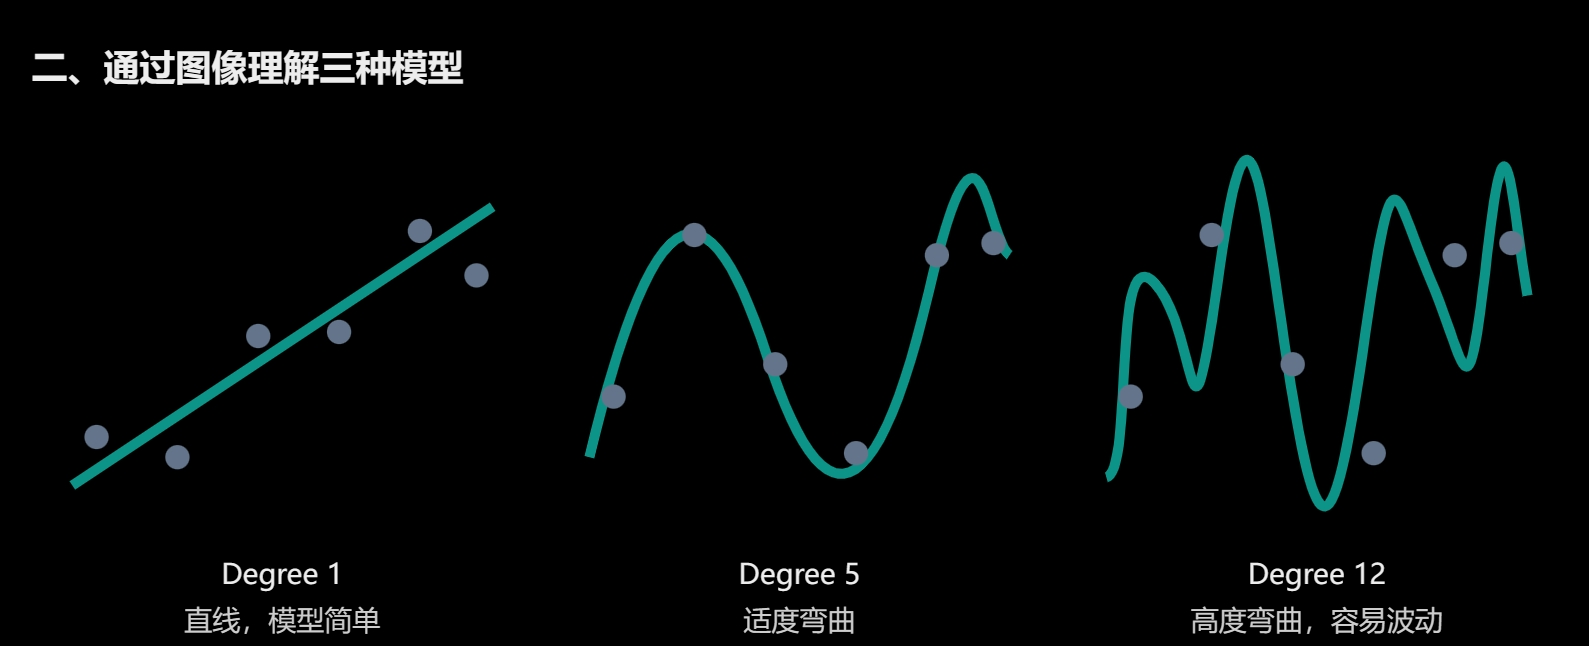

**Before running the plot:** which one do you expect to fit the training points most closely?

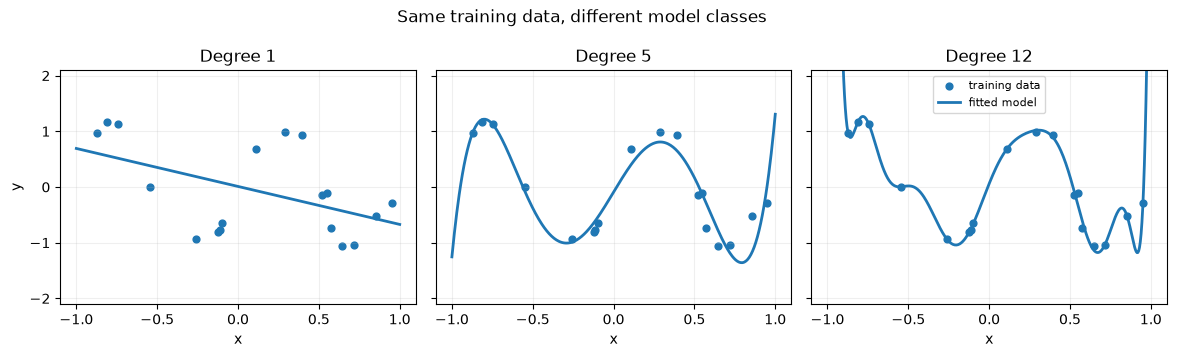

Note: curves that leave the vertical plot range are clipped.


In [5]:
# x_grid = np.linspace(-1, 1, 400)
# degrees_to_draw = [1, 5, 12]

# fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
# for ax, degree in zip(axes, degrees_to_draw):
#     v = fit_polynomial(x_train, y_train, degree)
#     ax.scatter(x_train, y_train, s=24, label="training data")
#     ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")
#     ax.set(title=f"Degree {degree}", xlabel="x", ylim=(-2.1, 2.1))
#     ax.grid(alpha=0.2)
# axes[0].set_ylabel("y")
# axes[-1].legend(loc="upper center", fontsize=8)
# fig.suptitle("Same training data, different model classes")
# fig.tight_layout()
# plt.show()
# print("Note: curves that leave the vertical plot range are clipped.")


# 使用 NumPy 的 linspace 函数，在 -1 到 1 之间均匀生成 400 个点（包含两个端点）
# 这些点用于绘制拟合曲线，而不是训练模型
x_grid = np.linspace(-1, 1, 400)

# 定义需要比较的多项式次数：1 次、5 次和 12 次
degrees_to_draw = [1, 5, 12]

# 创建一个包含 1 行、3 列子图的 Figure
# fig 是整张画布，axes 是包含三个子图 Axes 对象的数组
# figsize=(12, 3.6)：画布大小为 12 × 3.6 英寸
# sharex=True：三个子图共享 x 轴设置
# sharey=True：三个子图共享 y 轴设置
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)

# 使用 zip() 将子图对象与多项式次数一一配对
# 第一次循环：ax=axes[0]，degree=1
# 第二次循环：ax=axes[1]，degree=5
# 第三次循环：ax=axes[2]，degree=12
for ax, degree in zip(axes, degrees_to_draw):

    # 调用自定义函数 fit_polynomial()，拟合指定次数的多项式
    # x_train：训练数据的输入 x
    # y_train：训练数据的真实输出 y
    # degree：多项式次数
    # v：保存拟合得到的模型参数（具体结构取决于函数实现）
    v = fit_polynomial(x_train, y_train, degree)

    # 在当前子图中绘制训练数据散点图
    # x_train：散点的横坐标
    # y_train：散点的纵坐标
    # s=24：散点大小，单位是 points²
    # label="training data"：图例中显示的名称
    ax.scatter(x_train, y_train, s=24, label="training data")

    # 在当前子图中绘制模型拟合曲线
    # x_grid：生成曲线时使用的 400 个 x 坐标
    # predict_polynomial(x_grid, v)：根据参数 v 计算对应的预测 y 值
    # lw=2：曲线宽度为 2 points
    # label="fitted model"：图例中显示的名称
    ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")

    # 设置当前子图的标题、x 轴名称和 y 轴显示范围
    # title=f"Degree {degree}"：根据循环中的 degree 自动生成标题
    # xlabel="x"：设置 x 轴标签
    # ylim=(-2.1, 2.1)：将 y 轴显示范围限制在 -2.1 到 2.1
    ax.set(title=f"Degree {degree}", xlabel="x", ylim=(-2.1, 2.1))

    # 为当前子图添加网格线
    # alpha=0.2：透明度为 0.2，网格线比较淡
    ax.grid(alpha=0.2)

# 为第一个子图设置 y 轴标签
# 因为三个子图共享 y 轴，因此只需在左侧显示 y 标签
axes[0].set_ylabel("y")

# 在最后一个子图（axes[-1]）中显示图例
# loc="upper center"：将图例放在子图上方中央
# fontsize=8：图例字体大小为 8 points
axes[-1].legend(loc="upper center", fontsize=8)

# 为整张 Figure 设置总标题
fig.suptitle("Same training data, different model classes")

# 自动调整子图布局，尽量避免标题、标签和子图之间发生重叠
fig.tight_layout()

# 显示最终绘制的图像
plt.show()

# 输出提示信息
# 如果拟合曲线超出 y 轴的显示范围 (-2.1, 2.1)，超出的部分会被裁剪，不会显示
print("Note: curves that leave the vertical plot range are clipped.")

## 4. Does minimising training energy give good predictions? — coding task B

Recall: the **feature map $\phi_k$ is fixed**, we learnt $v$, and we **chose the loss to equal the energy**:

$$
\ell_{v,\phi_k}(x,y)=E_{v,\phi_k}(x,y)
=\bigl(\langle v,\phi_k(x)\rangle-y\bigr)^2.
$$

On $n$ input–output pairs, the *average loss* is the **mean squared error（均方误差） (MSE)**:

$$
\operatorname{MSE}=\frac1n\sum_{i=1}^n\bigl(\widehat y(x_i)-y_i\bigr)^2.
$$

We fitted $v$ to minimise this on the **training set**. We will evaluate the *same* loss on separate **validation examples**, which were not used to fit $v$.

**Complete the one-line `mse` function** using NumPy.

In [7]:
def mse(y, y_pred):
    # TODO B: compute the mean of the squared differences
    # 计算预测值与真实值的平方差，再求平均值
    return np.mean((y_pred - y) ** 2)

In [ ]:
# 创建真实值数组 y = [1.0, 3.0] 和预测值数组 y_pred = [2.0, 1.0]
# mse()：计算均方误差，预期结果为 ((1-2)**2 + (3-1)**2) / 2 = 2.5
# np.isclose()：判断计算结果是否接近 2.5，允许微小的浮点数误差
# assert：如果判断为 True，继续执行；否则抛出 AssertionError
# "Check task B."：断言失败时显示的错误信息
assert np.isclose(mse(np.array([1., 3.]), np.array([2., 1.])), 2.5), "Check task B."
print("Task B passed")

Task B passed


**Stop and predict.** If a model becomes increasingly flexible, what should happen to its *training* MSE? Must the *validation* MSE behave the same way?

Run the next cell to find out. Notice that every degree is fitted **only on the training set**.

Degree | Training MSE | Validation MSE
----------------------------------------
     1 |       0.4894 |         0.5738
     3 |       0.3578 |         0.5653
     5 |       0.0651 |         0.1033
     8 |       0.0099 |         0.0906
    12 |       0.0051 |        17.1651


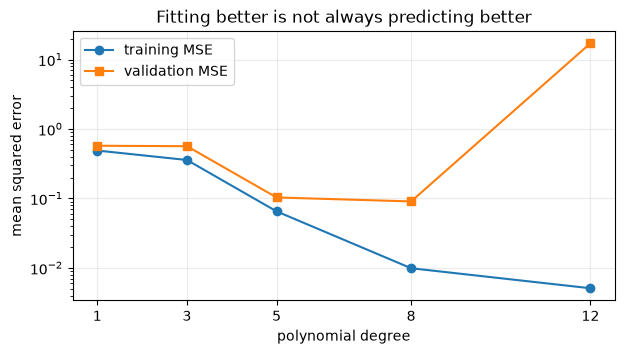

In [9]:
# degrees = [1, 3, 5, 8, 12]
# train_losses, val_losses = [], []

# for degree in degrees:
#     v = fit_polynomial(x_train, y_train, degree)
#     train_losses.append(mse(y_train, predict_polynomial(x_train, v)))
#     val_losses.append(mse(y_val, predict_polynomial(x_val, v)))

# print(f"{'Degree':>6} | {'Training MSE':>12} | {'Validation MSE':>14}")
# print("-" * 40)
# for degree, a, b in zip(degrees, train_losses, val_losses):
#     print(f"{degree:6d} | {a:12.4f} | {b:14.4f}")

# fig, ax = plt.subplots(figsize=(7, 3.5))
# ax.plot(degrees, train_losses, "o-", label="training MSE")
# ax.plot(degrees, val_losses, "s-", label="validation MSE")
# ax.set(xlabel="polynomial degree", ylabel="mean squared error", title="Fitting better is not always predicting better")
# ax.set_yscale("log")  # logarithmic scale: errors span a wide range
# ax.set_xticks(degrees)
# ax.grid(alpha=0.25)
# ax.legend()
# plt.show()

# 定义需要比较的多项式次数（Degree）
# 分别训练 1、3、5、8、12 次多项式模型，用于比较模型复杂度对预测效果的影响
degrees = [1, 3, 5, 8, 12]

# 初始化两个空列表
# train_losses：保存不同次数模型的训练集均方误差（Training MSE）
# val_losses：保存不同次数模型的验证集均方误差（Validation MSE）
train_losses, val_losses = [], []


# 遍历 degrees 中的每一个多项式次数
for degree in degrees:

    # 使用训练数据 x_train、y_train 拟合 degree 次多项式
    # fit_polynomial() 返回训练得到的多项式系数 v
    # 例如 degree=2 时，v 通常包含 [v0, v1, v2] 三个系数
    v = fit_polynomial(x_train, y_train, degree)

    # predict_polynomial(x_train, v)：使用训练好的模型预测训练集
    # mse(y_train, ...)：计算预测值与训练集真实值之间的均方误差
    # append()：将当前模型的 Training MSE 添加到 train_losses 列表末尾
    train_losses.append(mse(y_train, predict_polynomial(x_train, v)))

    # predict_polynomial(x_val, v)：使用同一个模型预测验证集
    # mse(y_val, ...)：计算验证集上的均方误差
    # append()：将当前模型的 Validation MSE 添加到 val_losses 列表末尾
    # 注意：验证集不参与模型参数 v 的拟合，只用于评价模型在未参与训练的数据上的表现
    val_losses.append(mse(y_val, predict_polynomial(x_val, v)))


# 打印表格标题
# f-string：格式化字符串
# {'Degree':>6}：将 Degree 右对齐，占据至少 6 个字符宽度
# {'Training MSE':>12}：右对齐，占据至少 12 个字符宽度
# {'Validation MSE':>14}：右对齐，占据至少 14 个字符宽度
# |：用于分隔不同列
print(f"{'Degree':>6} | {'Training MSE':>12} | {'Validation MSE':>14}")

# 打印 40 个连字符，作为表格标题与数据之间的分隔线
# Python 中字符串乘以整数表示重复该字符串
print("-" * 40)


# zip()：将三个列表中相同位置的元素组合起来
# degree：多项式次数
# a：对应次数模型的 Training MSE
# b：对应次数模型的 Validation MSE
for degree, a, b in zip(degrees, train_losses, val_losses):

    # 将每个模型的次数、训练误差和验证误差格式化输出
    # {degree:6d}：整数格式，宽度为 6，右对齐
    # {a:12.4f}：浮点数格式，宽度为 12，保留 4 位小数
    # {b:14.4f}：浮点数格式，宽度为 14，保留 4 位小数
    print(f"{degree:6d} | {a:12.4f} | {b:14.4f}")


# 创建 Matplotlib 图表
# fig：整张图（Figure）
# ax：当前坐标系（Axes）
# figsize=(7, 3.5)：图表大小为 7 × 3.5 英寸
fig, ax = plt.subplots(figsize=(7, 3.5))

# 绘制训练集 MSE 随多项式次数变化的曲线
# degrees：横坐标，表示多项式次数
# train_losses：纵坐标，表示训练误差
# "o-"：使用圆形标记（o），并用实线（-）连接数据点
# label：图例名称
ax.plot(degrees, train_losses, "o-", label="training MSE")

# 绘制验证集 MSE 随多项式次数变化的曲线
# val_losses：纵坐标，表示验证误差
# "s-"：使用方形标记（s），并用实线（-）连接数据点
# label：图例名称
ax.plot(degrees, val_losses, "s-", label="validation MSE")

# 设置坐标轴标签和图表标题
# xlabel：x 轴名称，多项式次数
# ylabel：y 轴名称，均方误差
# title：图表标题，意思是“拟合得更好不一定预测得更好”
ax.set(
    xlabel="polynomial degree",
    ylabel="mean squared error",
    title="Fitting better is not always predicting better"
)

# 将 y 轴设置为对数刻度（Logarithmic Scale）
# 适合展示数值跨度较大的误差
# 例如 0.001、0.01、0.1、1、10 可以在对数轴上等间距显示
# 注意：对数坐标要求绘制的 MSE 为正数，0 无法直接显示
ax.set_yscale("log")

# 设置 x 轴刻度
# 只显示 degrees 中指定的次数：1、3、5、8、12
ax.set_xticks(degrees)

# 添加网格线
# alpha=0.25：网格线透明度为 0.25，避免影响曲线观察
ax.grid(alpha=0.25)

# 显示图例，用于区分 Training MSE 和 Validation MSE
ax.legend()

# 显示最终图表
plt.show()

**Your decision:** Which polynomial degree would you choose, based on the validation results? Compare it with the degree that minimises training MSE. Explain your reasoning in one or two sentences to your partner.

The next cell implements the validation-based choice.

In [10]:
best_index = int(np.argmin(val_losses))
best_degree = degrees[best_index]
print(f"Smallest training MSE: degree {degrees[int(np.argmin(train_losses))]}")
print(f"Smallest validation MSE: degree {best_degree}")

Smallest training MSE: degree 12
Smallest validation MSE: degree 8


## 5. Reveal the test data

A **test set** is another set of examples, withheld until the model has been selected. It is for a final assessment, **not** for repeatedly changing the selected model.

The next cell loads the hidden test examples and reveals the underlying noise-free curve. It compares our validation-selected model with the most flexible candidate. **Run it only after choosing the degree above.**

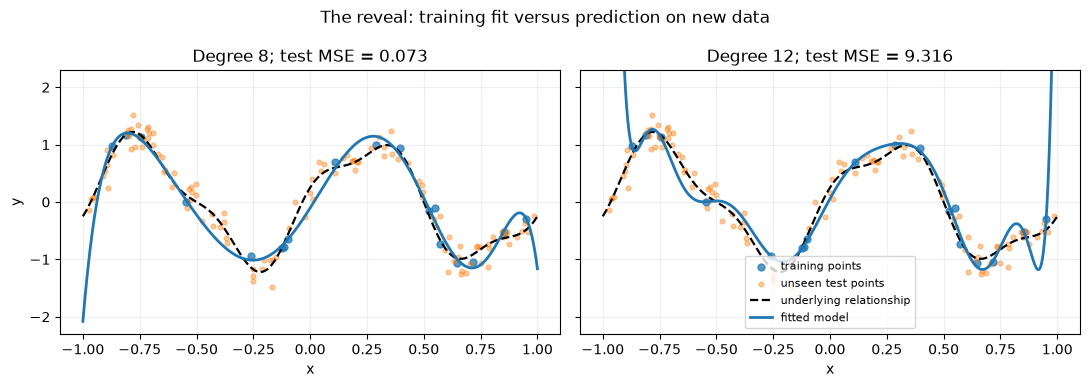

Some degree-12 predictions may extend well beyond the visible vertical range.


In [ ]:
# with np.load("lab1_reveal.npz") as reveal:
#     x_test, y_test = reveal["x_test"], reveal["y_test"]
#     x_true, y_true = reveal["x_grid"], reveal["y_true_grid"]

# fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharex=True, sharey=True)
# for ax, degree in zip(axes, [best_degree, 12]):
#     v = fit_polynomial(x_train, y_train, degree)
#     y_pred_test = predict_polynomial(x_test, v)
#     ax.scatter(x_train, y_train, s=25, alpha=0.75, label="training points")
#     ax.scatter(x_test, y_test, s=12, alpha=0.4, label="unseen test points")
#     ax.plot(x_true, y_true, "k--", lw=1.6, label="underlying relationship")
#     ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")
#     ax.set(title=f"Degree {degree}; test MSE = {mse(y_test, y_pred_test):.3f}",
#            xlabel="x", ylim=(-2.3, 2.3))
#     ax.grid(alpha=0.2)
# axes[0].set_ylabel("y")
# axes[-1].legend(fontsize=8, loc="lower center")
# fig.suptitle("The reveal: training fit versus prediction on new data")
# fig.tight_layout()
# plt.show()
# print("Some degree-12 predictions may extend well beyond the visible vertical range.")

# 使用 NumPy 的 np.load() 读取 .npz 格式的数据文件
# .npz 文件可以同时保存多个 NumPy 数组
# with ... as ...：上下文管理器，代码块结束后会自动关闭文件
# reveal：保存读取到的数据文件对象
with np.load("lab1_reveal.npz") as reveal:

    # 从文件中读取测试集（Test Set）
    # reveal["x_test"]：测试集的输入特征 x
    # reveal["y_test"]：测试集对应的真实标签 y
    # x_test 和 y_test 用于评价模型对未见过的数据的预测能力（Generalisation）
    x_test, y_test = reveal["x_test"], reveal["y_test"]

    # 从文件中读取真实关系曲线的数据
    # reveal["x_grid"]：真实曲线对应的 x 坐标
    # reveal["y_true_grid"]：这些 x 坐标对应的真实函数值
    # x_true 和 y_true 用于绘制 underlying relationship（数据背后的真实规律）
    # 注意：真实关系曲线仅用于可视化比较，不参与模型训练
    x_true, y_true = reveal["x_grid"], reveal["y_true_grid"]


# 创建 Matplotlib 图表
# fig：整个 Figure（画布）
# axes：包含两个 Axes（子图）对象的数组
# 1, 2：创建 1 行 2 列的子图
# figsize=(11, 3.9)：画布宽 11 英寸、高 3.9 英寸
# sharex=True：两个子图共享 x 轴设置
# sharey=True：两个子图共享 y 轴设置，便于比较预测曲线
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharex=True, sharey=True)


# zip()：将两个子图与对应的多项式次数一一配对
# 第一次循环：ax = axes[0]，degree = best_degree
# 第二次循环：ax = axes[1]，degree = 12
# best_degree：前面根据验证集表现选择出的最佳多项式次数
# 12：用于对比的高复杂度模型（Degree 12）
for ax, degree in zip(axes, [best_degree, 12]):

    # 使用训练集拟合 degree 次多项式
    # x_train、y_train：训练集数据
    # degree：当前模型的多项式次数
    # v：拟合得到的多项式系数向量
    # 注意：这里只使用训练数据拟合模型，没有使用测试数据训练
    v = fit_polynomial(x_train, y_train, degree)

    # 使用训练好的多项式模型预测测试集
    # x_test：测试集输入
    # v：训练得到的模型参数
    # y_pred_test：模型对测试集的预测结果
    y_pred_test = predict_polynomial(x_test, v)

    # 在当前子图中绘制训练集散点
    # x_train、y_train：训练数据的横坐标和纵坐标
    # s=25：散点大小为 25 points²
    # alpha=0.75：透明度为 0.75，数值越小越透明
    # label="training points"：图例名称
    ax.scatter(x_train, y_train, s=25, alpha=0.75, label="training points")

    # 在当前子图中绘制测试集散点
    # x_test、y_test：模型训练时没有见过的测试数据
    # s=12：散点大小为 12 points²，比训练集散点小
    # alpha=0.4：透明度为 0.4，使测试集散点显示得更淡
    # label="unseen test points"：图例名称
    # 作用：直观比较模型对训练数据和新数据的拟合效果
    ax.scatter(x_test, y_test, s=12, alpha=0.4, label="unseen test points")

    # 绘制数据背后的真实函数关系（Underlying Relationship）
    # x_true：真实函数曲线对应的 x 坐标
    # y_true：真实函数对应的 y 值
    # "k--"：k 表示黑色（black），-- 表示虚线
    # lw=1.6：线宽为 1.6 points
    # label：图例名称
    # 作用：将模型预测曲线与真实规律进行比较
    ax.plot(x_true, y_true, "k--", lw=1.6, label="underlying relationship")

    # 绘制当前模型的拟合曲线（Fitted Model）
    # x_grid：之前通过 np.linspace() 生成的 400 个绘图坐标
    # predict_polynomial(x_grid, v)：计算模型在这些坐标上的预测值
    # lw=2：曲线宽度为 2 points
    # label="fitted model"：图例名称
    # 作用：观察当前次数的多项式拟合出来的曲线形状
    ax.plot(x_grid, predict_polynomial(x_grid, v), lw=2, label="fitted model")

    # 设置当前子图的标题、x 轴名称和 y 轴范围
    # title=f"Degree {degree}; ..."：使用 f-string 动态生成标题
    # {degree}：显示当前模型的多项式次数
    # mse(y_test, y_pred_test)：计算测试集均方误差（Test MSE）
    # :.3f：将 MSE 格式化为保留 3 位小数的浮点数
    # xlabel="x"：设置 x 轴标签为 x
    # ylim=(-2.3, 2.3)：将 y 轴显示范围限制在 -2.3 到 2.3
    # 注意：超出显示范围的曲线会被裁剪，但不会影响 MSE 的计算
    ax.set(title=f"Degree {degree}; test MSE = {mse(y_test, y_pred_test):.3f}",
           xlabel="x", ylim=(-2.3, 2.3))

    # 为当前子图添加网格线
    # alpha=0.2：网格线透明度为 0.2，避免影响数据观察
    ax.grid(alpha=0.2)


# 为第一个子图设置 y 轴标签
# axes[0]：第一个子图
# 因为两个子图共享 y 轴，所以只需要在左侧显示一次 y 标签
axes[0].set_ylabel("y")

# 为最后一个子图添加图例
# axes[-1]：使用负数索引获取最后一个子图，即 axes[1]
# fontsize=8：图例字体大小为 8 points
# loc="lower center"：将图例放在子图下方中央
# 图例用于区分训练数据、测试数据、真实曲线和拟合曲线
axes[-1].legend(fontsize=8, loc="lower center")

# 设置整张 Figure 的总标题
# The reveal：揭示最终测试结果
# training fit versus prediction on new data：
# 比较模型对训练数据的拟合效果与对新数据的预测表现
fig.suptitle("The reveal: training fit versus prediction on new data")

# 自动调整子图布局
# 尽量避免标题、坐标轴标签和不同子图之间发生重叠
fig.tight_layout()

# 显示最终图表
plt.show()

# 输出提示信息
# Degree 12 的拟合曲线可能出现较大的波动
# 部分预测值可能超出 y 轴设定的显示范围 (-2.3, 2.3)
# 这些超出范围的曲线部分不会显示，但实际预测值仍然存在
print("Some degree-12 predictions may extend well beyond the visible vertical range.")

## Exit Questions (2–3 minutes)

Jot down brief answers:

1. We kept $\phi_{12}$ fixed and learnt only $v$. The resulting model has very small **average training energy**. Why can its **validation/test energy** nevertheless be large?
2. Why shouldn't we use the test set to decide which feature map $\phi_k$ to use?
3. What is the difference between **learning $v$ for a fixed $\phi_k$** and **learning $\phi$ itself**? Which did we do today?

**Takeaway:** An energy describes compatibility, a prediction rule chooses a low-energy output, and a loss specifies the learning objective. Today we used $\ell=E$, **fixed each feature map and learnt $v$**, then used held-out data to assess generalisation. In later labs we will learn the feature representation too.

---
## Optional extension (after class)

**More data.** The degree-12 model has 13 coefficients. What happens if we give it 100 training observations instead of 18? The following cell creates a larger dataset from the same underlying relationship. Compare training and validation MSE using your existing functions. (This extension uses the test data for *no* fitting or selection.)

In [12]:
extra_rng = np.random.default_rng(2026)
x_more = np.sort(extra_rng.uniform(-1, 1, size=100))
y_more = (np.sin(2 * np.pi * x_more)
          + 0.25 * np.cos(5 * np.pi * x_more)
          + extra_rng.normal(0, 0.17, size=len(x_more)))

for degree in [5, 12]:
    v_small = fit_polynomial(x_train, y_train, degree)
    v_large = fit_polynomial(x_more, y_more, degree)
    print(f"Degree {degree:2d}: validation MSE with 18 points = "
          f"{mse(y_val, predict_polynomial(x_val, v_small)):.4f}; "
          f"with 100 points = {mse(y_val, predict_polynomial(x_val, v_large)):.4f}")

Degree  5: validation MSE with 18 points = 0.1033; with 100 points = 0.1212
Degree 12: validation MSE with 18 points = 17.1651; with 100 points = 0.0587
